# Modelo 1: Intenção da pergunta (LarOuAyê)
**Disciplina:** Artificial Intelligence & Chatbot

**Objetivo:** dizer em qual assunto jurídico cai a dúvida do cidadão (matrícula, escritura, contrato, financiamento, FGTS, impostos, leilão, imóvel usado, fraude) ou se está **fora do escopo**.

**Regra do projeto:** *a IA identifica, o Java decide, o conteúdo jurídico fundamenta.* Este modelo **nunca escreve a resposta**.

> **Origem e limites dos dados (registrar no relatório).** As frases foram **escritas pelo grupo/assistente** como amostras sintéticas
> de perguntas reais sobre compra do primeiro imóvel. **Não houve coleta de usuários.** O conjunto de **teste** foi escrito à parte,
> com redação diferente, e **nunca recebe aumento de dados**. Por serem poucas frases, a acurácia é uma **estimativa otimista**:
> perguntas reais de cidadãos terão mais variação, erros de digitação e gírias.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # permite importar larouaye_ia
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from larouaye_ia import nucleo
pd.set_option('display.max_colwidth', 90)

## 1. Análise exploratória

In [2]:
treino, teste = nucleo.carregar('intencao')
print('treino:', treino.shape, '| teste:', teste.shape)
treino.sample(6, random_state=1)

treino: (690, 2) | teste: (40, 2)


,texto,rotulo
666,"Por favor, Posso usar a renda do meu marido para financiar?",FINANCIAMENTO
520,"boa tarde, preciso de advogado para fazer a escritura obrigado",ESCRITURA_REGISTRO
681,Pode me ajudar? Como ver quem e o verdadeiro dono do imovel? pode explicar?,MATRICULA_ONUS
23,"oi, meu nome esta sujo, consigo financiar me explica",FINANCIAMENTO
65,"Por favor, Como saber se o leilao e confiavel?",LEILAO
339,Alteraram minha declaracao de imposto de renda sem eu saber,FRAUDE_GOLPES


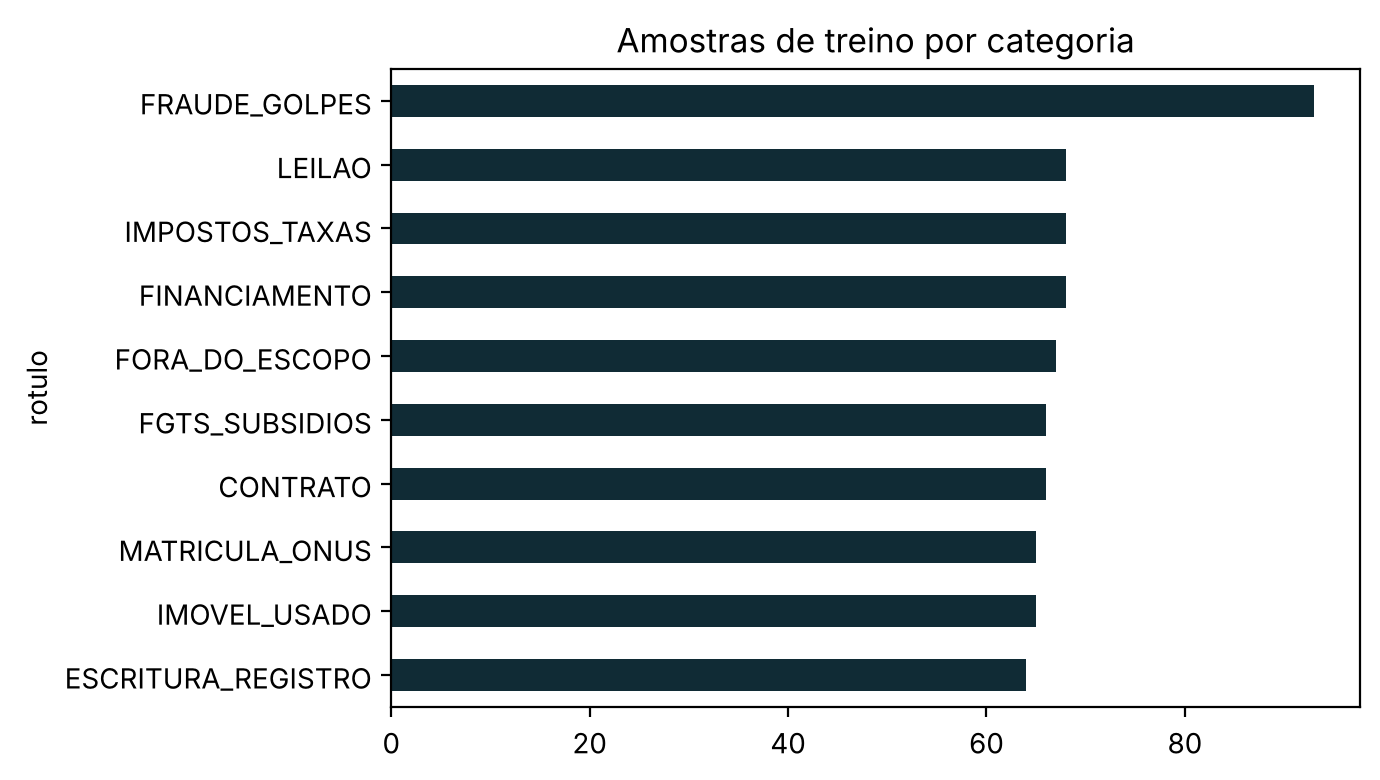

rotulo
FRAUDE_GOLPES         93
LEILAO                68
FINANCIAMENTO         68
IMPOSTOS_TAXAS        68
FORA_DO_ESCOPO        67
CONTRATO              66
FGTS_SUBSIDIOS        66
IMOVEL_USADO          65
MATRICULA_ONUS        65
ESCRITURA_REGISTRO    64
Name: count, dtype: int64

In [3]:
contagem = treino.rotulo.value_counts()
contagem.sort_values().plot(kind='barh', figsize=(7,4), color='#102b35')
plt.title('Amostras de treino por categoria'); plt.tight_layout(); plt.show()
contagem

In [4]:
print('Tamanho médio da pergunta (letras):', round(treino.texto.str.len().mean(), 1))
print('Categorias:', treino.rotulo.nunique())
print('Nulos:', int(treino.isna().sum().sum()), '| duplicadas:', int(treino.texto.duplicated().sum()))

Tamanho médio da pergunta (letras): 52.4
Categorias: 10
Nulos: 0 | duplicadas: 0


## 2. Pré-processamento e modelo
- **TF-IDF de caracteres (2 a 5)**: aguenta erro de digitação e variações (ex.: *imovel* / *imóvel*), e `strip_accents` ignora acentos.
- **Regressão Logística**: dá **probabilidade** por categoria, que usamos como confiança.

In [5]:
pipe = nucleo.pipeline_intencao()
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",'unicode'
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word or character n-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21 Since v0.21, if ``input`` is ``'filename'`` or ``'file'``, the data is first read from the file and then passed to the given callable analyzer.",'char_wb'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(2, ...)"
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode

In [6]:
res = nucleo.treinar_e_avaliar('intencao', pipe)
print('Acurácia no TESTE :', res['acuracia_teste'])
print('F1 macro no TESTE:', res['f1_macro_teste'])

Acurácia no TESTE : 0.9
F1 macro no TESTE: 0.9016


## 3. Avaliação detalhada

In [7]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
previsto = pipe.predict(teste.texto)
print(classification_report(teste.rotulo, previsto, zero_division=0))

                    precision    recall  f1-score   support

          CONTRATO       0.80      1.00      0.89         4
ESCRITURA_REGISTRO       1.00      0.75      0.86         4
    FGTS_SUBSIDIOS       0.80      1.00      0.89         4
     FINANCIAMENTO       0.60      0.75      0.67         4
    FORA_DO_ESCOPO       1.00      0.75      0.86         4
     FRAUDE_GOLPES       1.00      1.00      1.00         4
      IMOVEL_USADO       1.00      1.00      1.00         4
    IMPOSTOS_TAXAS       1.00      1.00      1.00         4
            LEILAO       1.00      0.75      0.86         4
    MATRICULA_ONUS       1.00      1.00      1.00         4

          accuracy                           0.90        40
         macro avg       0.92      0.90      0.90        40
      weighted avg       0.92      0.90      0.90        40



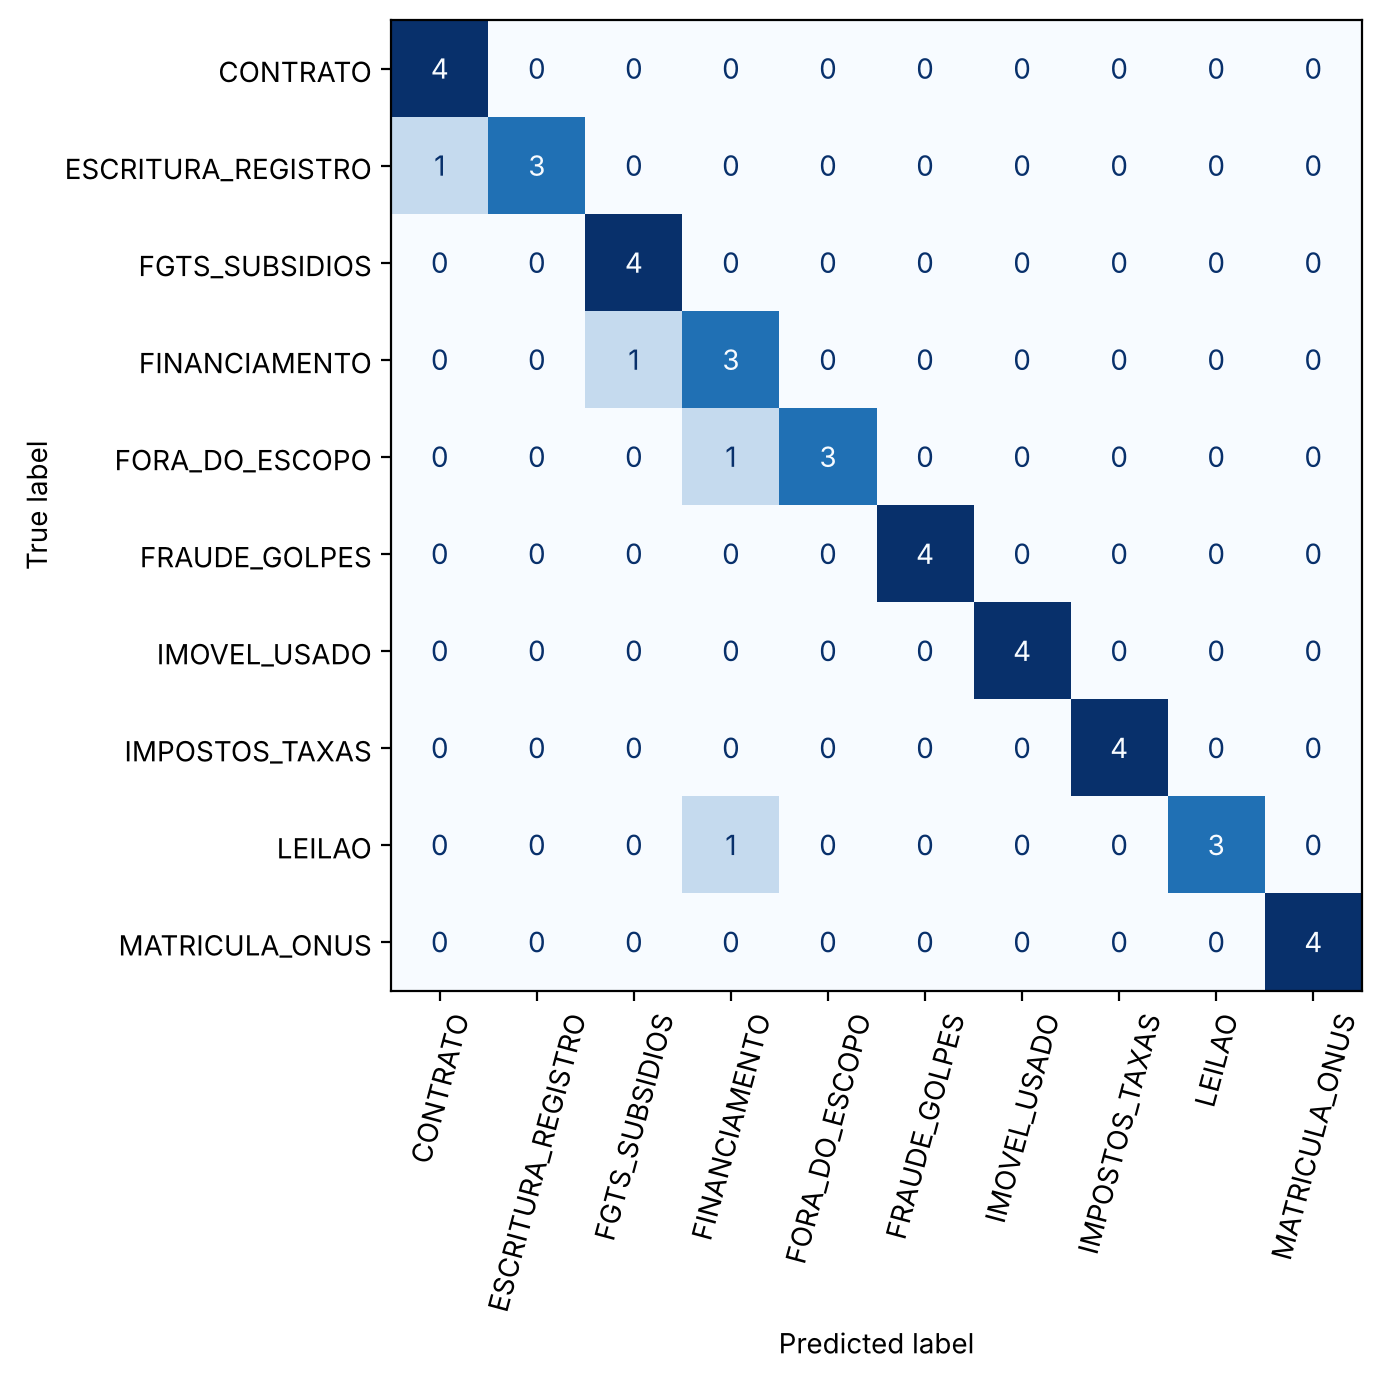

In [8]:
fig, ax = plt.subplots(figsize=(8,7))
ConfusionMatrixDisplay.from_predictions(teste.rotulo, previsto, xticks_rotation=75, cmap='Blues', ax=ax, colorbar=False)
plt.tight_layout(); plt.show()

In [9]:
erros = teste.assign(previsto=previsto, confianca=pipe.predict_proba(teste.texto).max(axis=1).round(2))
erros[erros.rotulo != erros.previsto]

,texto,rotulo,previsto,confianca
6,Quem so tem contrato de gaveta e dono do imovel?,ESCRITURA_REGISTRO,CONTRATO,0.63
14,Qual a parcela maxima em relacao ao salario?,FINANCIAMENTO,FGTS_SUBSIDIOS,0.45
26,Como funciona a compra de casa retomada pelo banco?,LEILAO,FINANCIAMENTO,0.57
39,Quanto custa uma passagem de aviao?,FORA_DO_ESCOPO,FINANCIAMENTO,0.46


## 4. Limiares de confiança (regra de decisão)
O modelo só **responde** com confiança alta. Entre os limiares, o sistema **pergunta** qual assunto a pessoa quer. Abaixo, diz que **não entendeu**.

In [10]:
from larouaye_ia import servico
prob = pipe.predict_proba(teste.texto); conf = prob.max(axis=1); acertou = (pipe.classes_[prob.argmax(axis=1)] == teste.rotulo.values)
print(f'Limiar de resposta direta: {servico.LIMIAR_RESPONDER} | de esclarecimento: {servico.LIMIAR_ESCLARECER}')
resp = conf >= servico.LIMIAR_RESPONDER
print('Respondidas direto:', int(resp.sum()), 'de', len(conf))
print('Acertos entre as respondidas direto:', round(float(acertou[resp].mean()), 3))
print('Erros que ficaram abaixo do limiar (seguros):', int((~acertou & ~resp).sum()), 'de', int((~acertou).sum()))

Limiar de resposta direta: 0.7 | de esclarecimento: 0.3
Respondidas direto: 29 de 40
Acertos entre as respondidas direto: 1.0
Erros que ficaram abaixo do limiar (seguros): 4 de 4


## 5. Exemplos reais (incluindo o caso de fraude do corretor)

In [11]:
exemplos = ['O corretor alterou meu IRRF e colocou minha esposa como dependente', 'Como sei se o imóvel tem escritura?', 'Posso usar FGTS na entrada?', 'Quero comprar um tênis', 'oi']
linhas = []
for q in exemplos:
    p = pipe.predict_proba([q])[0]; i = p.argmax(); linhas.append((q, pipe.classes_[i], round(float(p[i]), 2)))
pd.DataFrame(linhas, columns=['pergunta','categoria','confianca'])

,pergunta,categoria,confianca
0,O corretor alterou meu IRRF e colocou minha esposa como dependente,FRAUDE_GOLPES,0.98
1,Como sei se o imóvel tem escritura?,ESCRITURA_REGISTRO,0.93
2,Posso usar FGTS na entrada?,FGTS_SUBSIDIOS,0.98
3,Quero comprar um tênis,FORA_DO_ESCOPO,0.72
4,oi,FORA_DO_ESCOPO,0.18


## 6. Exportação
O modelo é salvo em `.joblib` e carregado pela API Flask (`app.py`).

In [12]:
caminho = nucleo.exportar(pipe, 'intencao'); print('salvo em', caminho.name, '|', round(caminho.stat().st_size/1024), 'KB')

salvo em modelo_intencao.joblib | 367 KB


## 7. Limitações e riscos
- Poucas frases sintéticas: reavaliar com perguntas reais antes de usar fora da apresentação.
- Confiança alta **não** significa resposta jurídica correta: o texto vem do catálogo revisado.
- O assunto *fora do escopo* é uma categoria treinada, mas assuntos muito diferentes podem escapar: o limiar protege.
- Não há dados pessoais no conjunto de treino.